# 🎭 Emotion Classification with Attention
Multi-class emotion classifier (**joy, sadness, anger, fear, surprise, disgust**) on GoEmotions.
Compares **LSTM**, **GRU**, **BiLSTM + Attention** (GloVe embeddings) and a fine-tuned **DistilBERT**,
visualizes attention weights, and deploys the best model with Gradio.

## 1. Setup


In [1]:
!pip -q install datasets gensim

import re, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from datasets import load_dataset
from sklearn.utils.class_weight import compute_class_weight

sns.set_style("whitegrid")

## 2. Load GoEmotions and map labels to 6 Ekman emotions


In [2]:
ds = load_dataset("google-research-datasets/go_emotions", "simplified")
label_names = ds["train"].features["labels"].feature.names

ekman_map = {
    "anger":   ["anger", "annoyance", "disapproval"],
    "disgust": ["disgust"],
    "fear":    ["fear", "nervousness"],
    "joy":     ["joy", "amusement", "approval", "excitement", "gratitude", "love",
                "optimism", "relief", "pride", "admiration", "desire", "caring"],
    "sadness": ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise":["surprise", "realization", "confusion", "curiosity"],
}
fine_to_ekman = {f: e for e, fs in ekman_map.items() for f in fs}
classes  = ["joy", "sadness", "anger", "fear", "surprise", "disgust"]
class2id = {c: i for i, c in enumerate(classes)}
id2class = {i: c for c, i in class2id.items()}

def to_single_label(label_ids):
    emos = {fine_to_ekman[label_names[i]] for i in label_ids if label_names[i] in fine_to_ekman}
    return class2id[emos.pop()] if len(emos) == 1 else None

def build(split):
    df = ds[split].to_pandas()
    df["label"] = df["labels"].apply(to_single_label)
    df = df.dropna(subset=["label"]).copy()
    df["label"] = df["label"].astype(int)
    return df[["text", "label"]].reset_index(drop=True)

train6, val6, test6 = build("train"), build("validation"), build("test")
print(len(train6), len(val6), len(test6))   # المتوقع: 28104 3527 3539
print(train6["label"].map(id2class).value_counts())

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

28104 3527 3539
label
joy         15809
anger        4590
surprise     4160
sadness      2455
fear          566
disgust       524
Name: count, dtype: int64


## 3. Text cleaning


In [3]:
def clean_text(text):
    text = str(text).lower()
    text = text.replace("’", "'").replace("‘", "'")
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"\[name\]|\[religion\]", " ", text)
    text = re.sub(r"n't\b", " n't", text)
    text = re.sub(r"'(s|m|re|ve|ll|d)\b", r" '\1", text)
    text = re.sub(r"([!?.,])\1+", r"\1", text)
    text = re.sub(r"([!?.,])", r" \1 ", text)
    text = re.sub(r"[^a-z0-9!?.,' ]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

for df in (train6, val6, test6):
    df["clean"] = df["text"].apply(clean_text)

print(train6["clean"].head(3).tolist())

['why the fuck is bayless isoing', 'to make her feel threatened', 'dirty southern wankers']


## 4. Vocabulary, padding and class weights

In [4]:
MAX_LEN, MAX_VOCAB = 32, 20000
PAD, UNK = "<pad>", "<unk>"

counter = Counter(w for s in train6["clean"] for w in s.split())
word2idx = {PAD: 0, UNK: 1}
for w, _ in counter.most_common(MAX_VOCAB - 2):
    word2idx[w] = len(word2idx)
idx2word = {i: w for w, i in word2idx.items()}
print("vocab size:", len(word2idx), "| unique words:", len(counter))

def encode(texts, max_len=MAX_LEN):
    X = np.zeros((len(texts), max_len), dtype="int32")
    for i, s in enumerate(texts):
        ids = [word2idx.get(w, 1) for w in s.split()][:max_len]
        X[i, :len(ids)] = ids
    return X

X_train, X_val, X_test = (encode(d["clean"]) for d in (train6, val6, test6))
y_train, y_val, y_test = (d["label"].values for d in (train6, val6, test6))
print(X_train.shape, X_val.shape, X_test.shape)

weights = compute_class_weight("balanced", classes=np.arange(6), y=y_train)
class_weight = {i: w for i, w in enumerate(weights)}
print({id2class[i]: round(w, 2) for i, w in class_weight.items()})

np.savez("data_seq.npz", X_train=X_train, X_val=X_val, X_test=X_test,
         y_train=y_train, y_val=y_val, y_test=y_test)
with open("vocab.pkl", "wb") as f:
    pickle.dump({"word2idx": word2idx, "max_len": MAX_LEN, "classes": classes}, f)

vocab size: 20000 | unique words: 20378
(28104, 32) (3527, 32) (3539, 32)
{'joy': np.float64(0.3), 'sadness': np.float64(1.91), 'anger': np.float64(1.02), 'fear': np.float64(8.28), 'surprise': np.float64(1.13), 'disgust': np.float64(8.94)}


## 5. GloVe embeddings (100d)

In [5]:
import gensim.downloader as api
glove = api.load("glove-wiki-gigaword-100")
EMB_DIM = glove.vector_size

rng = np.random.default_rng(42)
vocab_size = len(word2idx)
embedding_matrix = np.zeros((vocab_size, EMB_DIM), dtype="float32")
missing = []

for word, idx in word2idx.items():
    if idx == 0:
        continue
    if word in glove.key_to_index:
        embedding_matrix[idx] = glove[word]
    else:
        embedding_matrix[idx] = rng.normal(scale=0.1, size=EMB_DIM)
        missing.append(word)

found = vocab_size - 1 - len(missing)
print(f"Found in GloVe: {found}/{vocab_size - 1} ({found/(vocab_size-1):.1%})")
print("Sample missing words:", missing[:30])

total = sum(counter[w] for w in word2idx if w in counter and w not in (PAD, UNK))
miss  = sum(counter[w] for w in set(missing) if w in counter)
print(f"Token coverage: {1 - miss/total:.2%}")

np.save("embedding_matrix.npy", embedding_matrix)

[==================================================] 100.0% 128.1/128.1MB downloaded
Found in GloVe: 17587/19999 (87.9%)
Sample missing words: ['<unk>', 'lmao', 'hahaha', 'tbh', 'idk', 'subreddit', 'upvote', 'downvoted', "y'all", 'downvote', 'dumbass', 'upvotes', 'cakeday', 'upvoted', 'downvotes', 'nsfw', 'hahahaha', 'fortnite', 'damnit', 'incels', 'incel', 'cringy', 'brexit', 'unironically', 'youve', 'emoji', 'subreddits', 'cringey', 'downvoting', 'hahah']
Token coverage: 99.12%


In [6]:
import tensorflow as tf
from tensorflow.keras.layers import Embedding
from tensorflow.keras.initializers import Constant

def make_embedding(trainable=False):
    return Embedding(input_dim=vocab_size, output_dim=EMB_DIM,
                     embeddings_initializer=Constant(embedding_matrix),
                     trainable=trainable, mask_zero=True, name="embedding")
print(tf.__version__)

2.21.0


## 6. Training utilities, LSTM and GRU

In [9]:
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

tf.keras.utils.set_random_seed(42)
results = {}

def train_model(model, name, epochs=30, batch_size=64):
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    es = callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                 restore_best_weights=True)
    hist = model.fit(X_train, y_train,
                     validation_data=(X_val, y_val),
                     epochs=epochs, batch_size=batch_size,
                     class_weight=class_weight,
                     callbacks=[es], verbose=2)
    return hist

In [10]:
def evaluate_model(model, name):
    probs = model.predict(X_test, verbose=0)
    pred = probs.argmax(1)
    acc = accuracy_score(y_test, pred)
    f1  = f1_score(y_test, pred, average="macro")
    results[name] = {"accuracy": acc, "macro_f1": f1}
    print(f"\n{name} | Accuracy: {acc:.4f} | Macro F1: {f1:.4f}\n")
    print(classification_report(y_test, pred, target_names=classes, digits=3))

    cm = confusion_matrix(y_test, pred, normalize="true")
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=classes, yticklabels=classes)
    plt.title(f"{name} - normalized confusion matrix")
    plt.ylabel("True"); plt.xlabel("Predicted")
    plt.show()


In [11]:
def plot_history(hist, name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(hist.history["loss"], label="train")
    ax[0].plot(hist.history["val_loss"], label="val")
    ax[0].set_title(f"{name} loss"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train")
    ax[1].plot(hist.history["val_accuracy"], label="val")
    ax[1].set_title(f"{name} accuracy"); ax[1].legend()
    plt.show()

In [12]:
def build_rnn(cell, trainable, units=128):
    inp = layers.Input(shape=(MAX_LEN,))
    x = make_embedding(trainable)(inp)
    x = layers.SpatialDropout1D(0.2)(x)
    x = cell(units)(x)                       # LSTM أو GRU (آخر hidden state)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(6, activation="softmax")(x)
    return models.Model(inp, out)

def build_lstm(trainable): return build_rnn(layers.LSTM, trainable)
def build_gru(trainable):  return build_rnn(layers.GRU,  trainable)

### Sanity check: empty sequences
A row of only padding breaks the cuDNN RNN kernels, so empty rows are replaced with `<unk>`.

In [15]:
for name, X in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(name, "empty rows:", int((X.sum(1) == 0).sum()))

train empty rows: 1
val empty rows: 0
test empty rows: 0


In [16]:
for X in (X_train, X_val, X_test):
    empty = X.sum(1) == 0
    X[empty, 0] = 1          # <unk> بدل صف فاضي

for name, X in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(name, "empty rows:", int((X.sum(1) == 0).sum()))

np.savez("data_seq.npz", X_train=X_train, X_val=X_val, X_test=X_test,
         y_train=y_train, y_val=y_val, y_test=y_test)

train empty rows: 0
val empty rows: 0
test empty rows: 0


### LSTM (frozen vs. trainable GloVe)

==================== LSTM (trainable=False)
Epoch 1/30
440/440 - 7s - 16ms/step - accuracy: 0.4021 - loss: 1.6154 - val_accuracy: 0.5892 - val_loss: 1.2482
Epoch 2/30
440/440 - 3s - 8ms/step - accuracy: 0.5441 - loss: 1.3503 - val_accuracy: 0.6325 - val_loss: 1.0615
Epoch 3/30
440/440 - 4s - 8ms/step - accuracy: 0.5861 - loss: 1.1835 - val_accuracy: 0.6657 - val_loss: 0.9905
Epoch 4/30
440/440 - 4s - 9ms/step - accuracy: 0.6095 - loss: 1.0893 - val_accuracy: 0.6929 - val_loss: 0.9070
Epoch 5/30
440/440 - 3s - 8ms/step - accuracy: 0.6231 - loss: 1.0402 - val_accuracy: 0.6864 - val_loss: 0.9192
Epoch 6/30
440/440 - 3s - 8ms/step - accuracy: 0.6349 - loss: 0.9913 - val_accuracy: 0.6966 - val_loss: 0.8708
Epoch 7/30
440/440 - 4s - 10ms/step - accuracy: 0.6479 - loss: 0.9603 - val_accuracy: 0.6907 - val_loss: 0.8773
Epoch 8/30
440/440 - 4s - 9ms/step - accuracy: 0.6530 - loss: 0.9251 - val_accuracy: 0.7026 - val_loss: 0.8467
Epoch 9/30
440/440 - 3s - 7ms/step - accuracy: 0.6629 - loss: 0.89

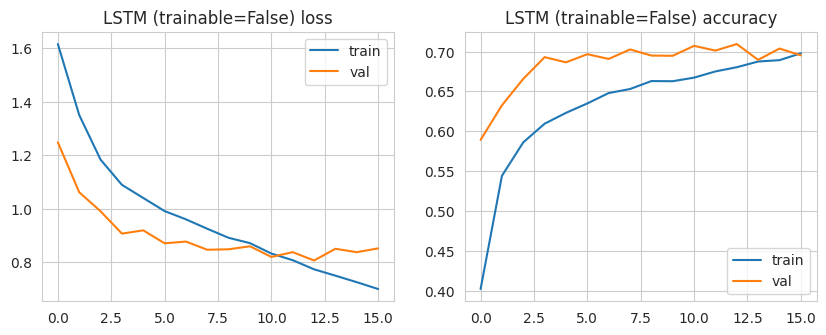


LSTM (trainable=False) | Accuracy: 0.6917 | Macro F1: 0.5867

              precision    recall  f1-score   support

         joy      0.891     0.768     0.825      1937
     sadness      0.473     0.591     0.525       298
       anger      0.518     0.496     0.507       609
        fear      0.470     0.729     0.571        85
    surprise      0.574     0.698     0.630       533
     disgust      0.363     0.636     0.462        77

    accuracy                          0.692      3539
   macro avg      0.548     0.653     0.587      3539
weighted avg      0.722     0.692     0.701      3539



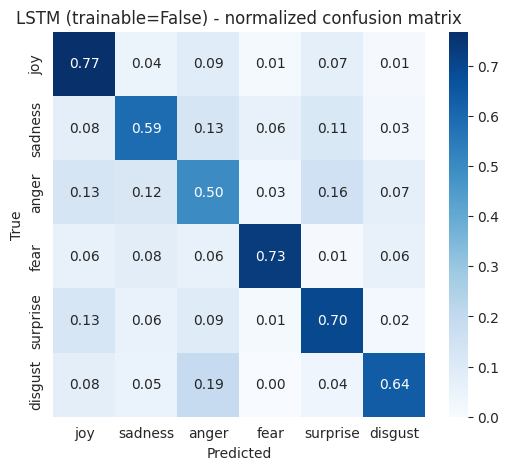

==================== LSTM (trainable=True)
Epoch 1/30
440/440 - 5s - 12ms/step - accuracy: 0.4380 - loss: 1.5559 - val_accuracy: 0.6090 - val_loss: 1.1637
Epoch 2/30
440/440 - 4s - 10ms/step - accuracy: 0.6522 - loss: 1.0671 - val_accuracy: 0.7168 - val_loss: 0.8533
Epoch 3/30
440/440 - 4s - 9ms/step - accuracy: 0.7207 - loss: 0.8301 - val_accuracy: 0.7332 - val_loss: 0.7949
Epoch 4/30
440/440 - 4s - 8ms/step - accuracy: 0.7531 - loss: 0.6975 - val_accuracy: 0.7426 - val_loss: 0.7672
Epoch 5/30
440/440 - 4s - 9ms/step - accuracy: 0.7816 - loss: 0.5871 - val_accuracy: 0.7355 - val_loss: 0.7949
Epoch 6/30
440/440 - 4s - 10ms/step - accuracy: 0.8035 - loss: 0.5033 - val_accuracy: 0.7360 - val_loss: 0.8186
Epoch 7/30
440/440 - 5s - 11ms/step - accuracy: 0.8284 - loss: 0.4201 - val_accuracy: 0.7295 - val_loss: 0.8569


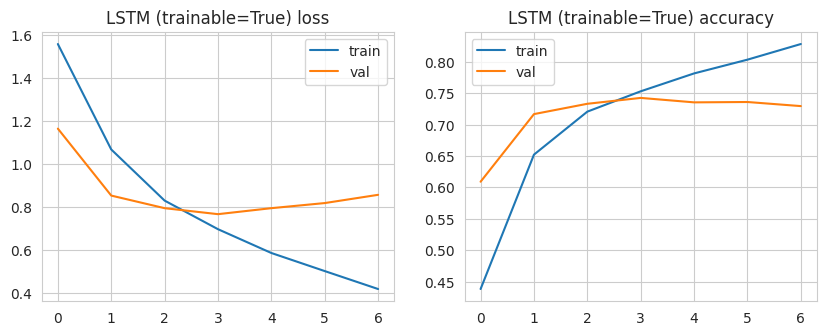


LSTM (trainable=True) | Accuracy: 0.7251 | Macro F1: 0.6359

              precision    recall  f1-score   support

         joy      0.922     0.773     0.841      1937
     sadness      0.549     0.624     0.584       298
       anger      0.548     0.619     0.581       609
        fear      0.524     0.776     0.626        85
    surprise      0.603     0.730     0.660       533
     disgust      0.432     0.662     0.523        77

    accuracy                          0.725      3539
   macro avg      0.596     0.697     0.636      3539
weighted avg      0.758     0.725     0.735      3539



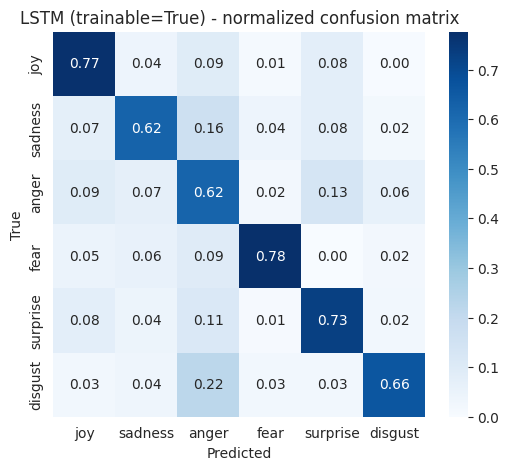

In [17]:
for trainable in (False, True):
    name = f"LSTM (trainable={trainable})"
    print("=" * 20, name)
    m = build_lstm(trainable)
    h = train_model(m, name)
    plot_history(h, name)
    evaluate_model(m, name)
    m.save(f"lstm_{'ft' if trainable else 'frozen'}.keras")

### GRU (frozen vs. trainable GloVe)

==================== GRU (trainable=False)
Epoch 1/30
440/440 - 5s - 11ms/step - accuracy: 0.3860 - loss: 1.6045 - val_accuracy: 0.5965 - val_loss: 1.1935
Epoch 2/30
440/440 - 3s - 7ms/step - accuracy: 0.5533 - loss: 1.2431 - val_accuracy: 0.6615 - val_loss: 0.9904
Epoch 3/30
440/440 - 4s - 10ms/step - accuracy: 0.5926 - loss: 1.1069 - val_accuracy: 0.6839 - val_loss: 0.8997
Epoch 4/30
440/440 - 3s - 8ms/step - accuracy: 0.6232 - loss: 1.0402 - val_accuracy: 0.6864 - val_loss: 0.8981
Epoch 5/30
440/440 - 3s - 7ms/step - accuracy: 0.6350 - loss: 0.9891 - val_accuracy: 0.6881 - val_loss: 0.8712
Epoch 6/30
440/440 - 3s - 7ms/step - accuracy: 0.6470 - loss: 0.9511 - val_accuracy: 0.6992 - val_loss: 0.8471
Epoch 7/30
440/440 - 4s - 10ms/step - accuracy: 0.6570 - loss: 0.9196 - val_accuracy: 0.7046 - val_loss: 0.8309
Epoch 8/30
440/440 - 3s - 7ms/step - accuracy: 0.6620 - loss: 0.8871 - val_accuracy: 0.7136 - val_loss: 0.8191
Epoch 9/30
440/440 - 3s - 7ms/step - accuracy: 0.6711 - loss: 0.85

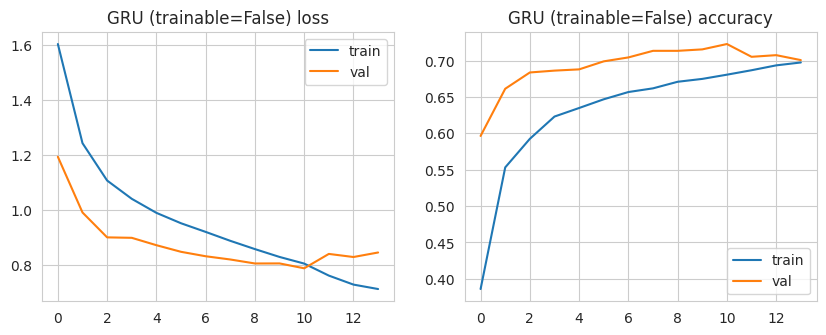


GRU (trainable=False) | Accuracy: 0.7098 | Macro F1: 0.6164

              precision    recall  f1-score   support

         joy      0.888     0.776     0.829      1937
     sadness      0.489     0.621     0.547       298
       anger      0.547     0.555     0.551       609
        fear      0.474     0.753     0.582        85
    surprise      0.607     0.700     0.650       533
     disgust      0.475     0.623     0.539        77

    accuracy                          0.710      3539
   macro avg      0.580     0.671     0.616      3539
weighted avg      0.735     0.710     0.718      3539



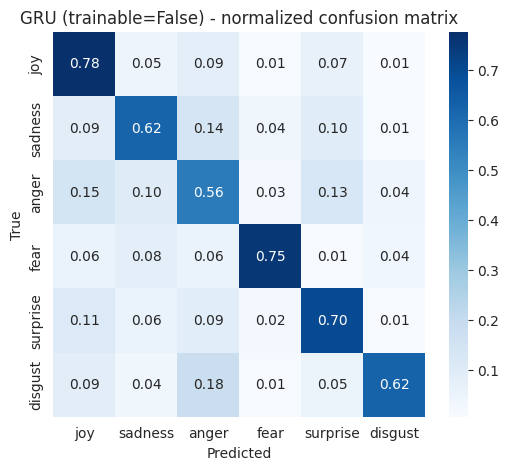

==================== GRU (trainable=True)
Epoch 1/30
440/440 - 6s - 14ms/step - accuracy: 0.4425 - loss: 1.5272 - val_accuracy: 0.6666 - val_loss: 0.9862
Epoch 2/30
440/440 - 4s - 8ms/step - accuracy: 0.6721 - loss: 0.9799 - val_accuracy: 0.7318 - val_loss: 0.7942
Epoch 3/30
440/440 - 4s - 8ms/step - accuracy: 0.7251 - loss: 0.7959 - val_accuracy: 0.7426 - val_loss: 0.7663
Epoch 4/30
440/440 - 5s - 10ms/step - accuracy: 0.7547 - loss: 0.6861 - val_accuracy: 0.7443 - val_loss: 0.7592
Epoch 5/30
440/440 - 4s - 8ms/step - accuracy: 0.7807 - loss: 0.5891 - val_accuracy: 0.7341 - val_loss: 0.8122
Epoch 6/30
440/440 - 4s - 8ms/step - accuracy: 0.8079 - loss: 0.4956 - val_accuracy: 0.7270 - val_loss: 0.8339
Epoch 7/30
440/440 - 4s - 10ms/step - accuracy: 0.8307 - loss: 0.4183 - val_accuracy: 0.7341 - val_loss: 0.8480


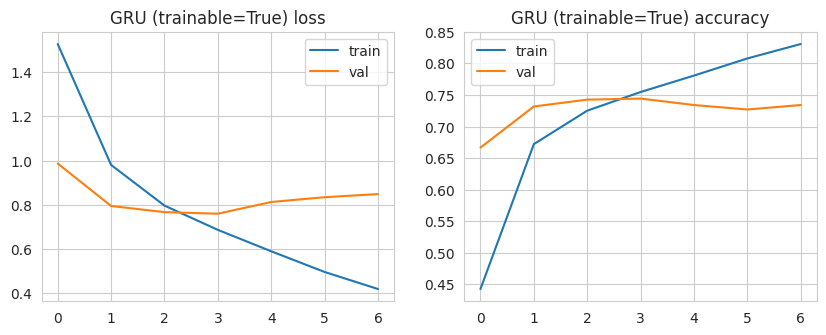


GRU (trainable=True) | Accuracy: 0.7321 | Macro F1: 0.6289

              precision    recall  f1-score   support

         joy      0.926     0.777     0.845      1937
     sadness      0.566     0.601     0.583       298
       anger      0.572     0.657     0.612       609
        fear      0.475     0.776     0.589        85
    surprise      0.634     0.728     0.678       533
     disgust      0.356     0.675     0.466        77

    accuracy                          0.732      3539
   macro avg      0.588     0.702     0.629      3539
weighted avg      0.767     0.732     0.743      3539



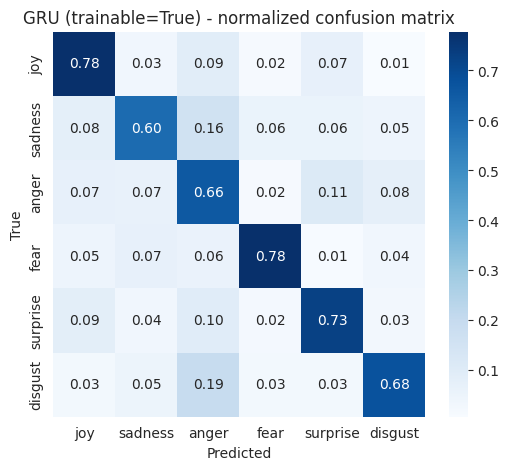

In [18]:
for trainable in (False, True):
    name = f"GRU (trainable={trainable})"
    print("=" * 20, name)
    m = build_gru(trainable)
    h = train_model(m, name)
    plot_history(h, name)
    evaluate_model(m, name)
    m.save(f"gru_{'ft' if trainable else 'frozen'}.keras")

In [19]:
pd.DataFrame(results).T.round(4).sort_values("macro_f1", ascending=False)

,accuracy,macro_f1
LSTM (trainable=True),0.7251,0.6359
GRU (trainable=True),0.7321,0.6289
GRU (trainable=False),0.7098,0.6164
LSTM (trainable=False),0.6917,0.5867


## 7. BiLSTM + Attention

In [20]:
@tf.keras.utils.register_keras_serializable(package="emo")
class AttentionLayer(layers.Layer):
    """Additive attention: score_t = v^T tanh(W h_t)  ->  softmax  ->  weighted sum"""
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.W = layers.Dense(units, activation="tanh")
        self.v = layers.Dense(1, use_bias=False)

    def call(self, inputs):
        h, ids = inputs                                    # h: (B,T,D) | ids: (B,T)
        mask = tf.not_equal(ids, 0)                        # الـ padding متاخدش attention
        score = tf.squeeze(self.v(self.W(h)), axis=-1)     # (B,T)
        score = tf.where(mask, score, tf.constant(-1e9, score.dtype))
        w = tf.nn.softmax(score, axis=-1)                  # (B,T) بيجمعوا 1
        context = tf.reduce_sum(h * tf.expand_dims(w, -1), axis=1)   # (B,D)
        return context, w

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"units": self.units})
        return cfg

In [21]:
def build_bilstm_attn(trainable, units=128):
    ids = layers.Input(shape=(MAX_LEN,), dtype="int32")
    x = make_embedding(trainable)(ids)
    x = layers.SpatialDropout1D(0.2)(x)
    h = layers.Bidirectional(layers.LSTM(units, return_sequences=True))(x)   # (B,T,256)
    ctx, w = AttentionLayer(64, name="attention")([h, ids])
    ctx = layers.Dropout(0.4)(ctx)
    out = layers.Dense(6, activation="softmax")(ctx)
    train_model_ = models.Model(ids, out)
    attn_model_  = models.Model(ids, [out, w])     # لنفس الـ layers
    return train_model_, attn_model_

m, _ = build_bilstm_attn(True)
m.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attention' (of type AttentionLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 32, 100)   │  2,000,000 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_6 │ (None, 32, 100)   │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_6         │ (None, 32)        │          0 │ input_layer_6[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 32, 256)   │    234,496 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_6[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 256),     │     16,512 │ bidirectional[0]… │
│ (AttentionLayer)    │ (None, 32)]       │            │ input_layer_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 256)       │          0 │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 6)         │      1,542 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,252,550 (8.59 MB)

 Trainable params: 2,252,550 (8.59 MB)

 Non-trainable params: 0 (0.00 B)

==================== BiLSTM+Attention (trainable=False)
Epoch 1/30
440/440 - 17s - 38ms/step - accuracy: 0.4753 - loss: 1.4069 - val_accuracy: 0.6731 - val_loss: 0.9979
Epoch 2/30
440/440 - 7s - 17ms/step - accuracy: 0.6126 - loss: 1.1030 - val_accuracy: 0.6884 - val_loss: 0.9448
Epoch 3/30
440/440 - 6s - 13ms/step - accuracy: 0.6395 - loss: 1.0200 - val_accuracy: 0.6878 - val_loss: 0.9138
Epoch 4/30
440/440 - 5s - 11ms/step - accuracy: 0.6505 - loss: 0.9734 - val_accuracy: 0.6997 - val_loss: 0.8696
Epoch 5/30
440/440 - 6s - 14ms/step - accuracy: 0.6628 - loss: 0.9404 - val_accuracy: 0.6983 - val_loss: 0.8836
Epoch 6/30
440/440 - 5s - 11ms/step - accuracy: 0.6726 - loss: 0.8952 - val_accuracy: 0.7046 - val_loss: 0.8498
Epoch 7/30
440/440 - 6s - 13ms/step - accuracy: 0.6790 - loss: 0.8631 - val_accuracy: 0.7105 - val_loss: 0.8405
Epoch 8/30
440/440 - 10s - 23ms/step - accuracy: 0.6860 - loss: 0.8299 - val_accuracy: 0.6796 - val_loss: 0.9180
Epoch 9/30
440/440 - 7s - 17ms/step - accuracy

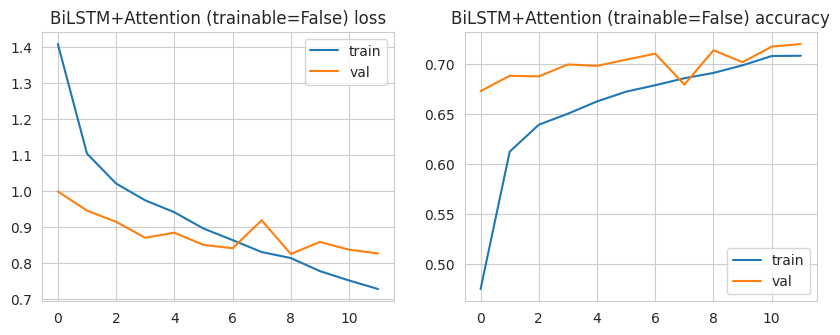


BiLSTM+Attention (trainable=False) | Accuracy: 0.7056 | Macro F1: 0.6164

              precision    recall  f1-score   support

         joy      0.925     0.745     0.826      1937
     sadness      0.517     0.604     0.557       298
       anger      0.506     0.622     0.558       609
        fear      0.427     0.859     0.570        85
    surprise      0.627     0.690     0.657       533
     disgust      0.431     0.688     0.530        77

    accuracy                          0.706      3539
   macro avg      0.572     0.702     0.616      3539
weighted avg      0.751     0.706     0.719      3539



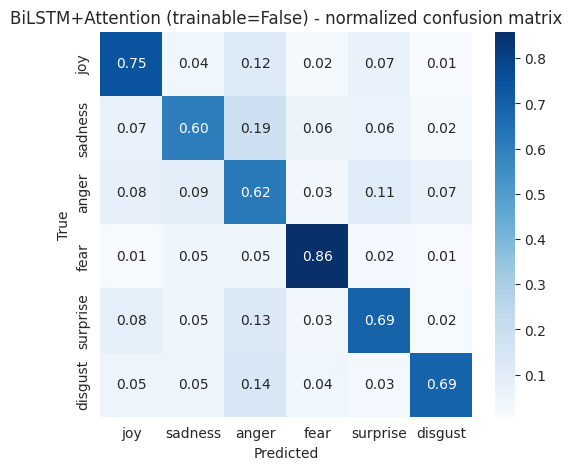

==================== BiLSTM+Attention (trainable=True)
Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attention' (of type AttentionLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


440/440 - 8s - 18ms/step - accuracy: 0.5374 - loss: 1.3108 - val_accuracy: 0.6997 - val_loss: 0.9055
Epoch 2/30
440/440 - 6s - 14ms/step - accuracy: 0.6947 - loss: 0.9223 - val_accuracy: 0.7377 - val_loss: 0.7930
Epoch 3/30
440/440 - 5s - 12ms/step - accuracy: 0.7348 - loss: 0.7895 - val_accuracy: 0.7434 - val_loss: 0.7679
Epoch 4/30
440/440 - 6s - 14ms/step - accuracy: 0.7589 - loss: 0.6951 - val_accuracy: 0.7185 - val_loss: 0.8162
Epoch 5/30
440/440 - 5s - 12ms/step - accuracy: 0.7802 - loss: 0.6072 - val_accuracy: 0.7474 - val_loss: 0.7548
Epoch 6/30
440/440 - 6s - 14ms/step - accuracy: 0.8049 - loss: 0.5142 - val_accuracy: 0.7536 - val_loss: 0.7554
Epoch 7/30
440/440 - 10s - 22ms/step - accuracy: 0.8319 - loss: 0.4289 - val_accuracy: 0.7536 - val_loss: 0.7662
Epoch 8/30
440/440 - 6s - 14ms/step - accuracy: 0.8472 - loss: 0.3769 - val_accuracy: 0.7335 - val_loss: 0.8181


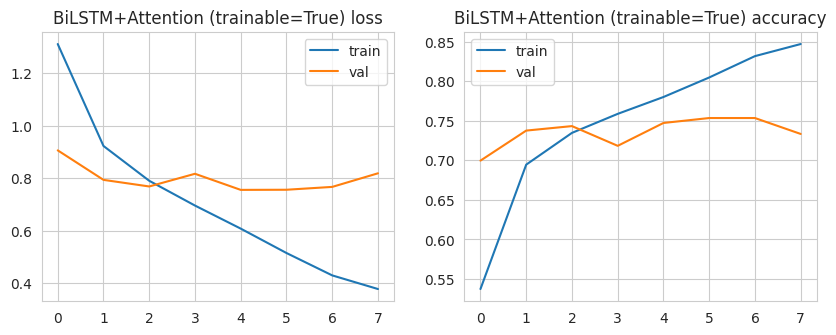


BiLSTM+Attention (trainable=True) | Accuracy: 0.7426 | Macro F1: 0.6526

              precision    recall  f1-score   support

         joy      0.927     0.783     0.849      1937
     sadness      0.561     0.648     0.601       298
       anger      0.583     0.660     0.619       609
        fear      0.534     0.835     0.651        85
    surprise      0.640     0.741     0.687       533
     disgust      0.417     0.649     0.508        77

    accuracy                          0.743      3539
   macro avg      0.610     0.719     0.653      3539
weighted avg      0.773     0.743     0.752      3539



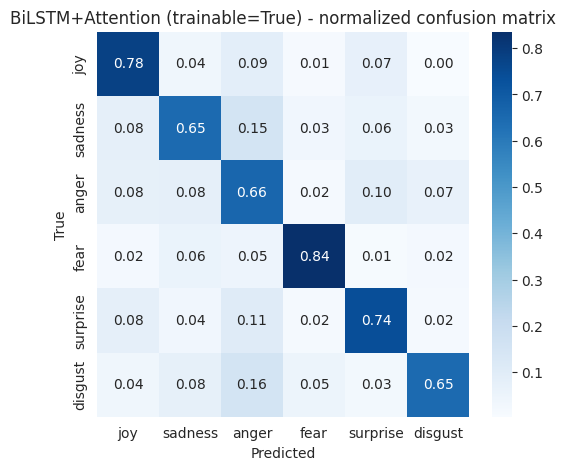

In [22]:
attn_models = {}
for trainable in (False, True):
    name = f"BiLSTM+Attention (trainable={trainable})"
    print("=" * 20, name)
    m, am = build_bilstm_attn(trainable)
    h = train_model(m, name)
    plot_history(h, name)
    evaluate_model(m, name)
    am.save(f"bilstm_attn_{'ft' if trainable else 'frozen'}.keras")
    attn_models[trainable] = am

In [23]:
pd.DataFrame(results).T.round(4).sort_values("macro_f1", ascending=False)

,accuracy,macro_f1
BiLSTM+Attention (trainable=True),0.7426,0.6526
LSTM (trainable=True),0.7251,0.6359
GRU (trainable=True),0.7321,0.6289
GRU (trainable=False),0.7098,0.6164
BiLSTM+Attention (trainable=False),0.7056,0.6164
LSTM (trainable=False),0.6917,0.5867


### Save / reload models (Google Drive)

In [24]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/emotion_project
!cp *.keras data_seq.npz vocab.pkl embedding_matrix.npy /content/drive/MyDrive/emotion_project/

Mounted at /content/drive


In [25]:
am = tf.keras.models.load_model("/content/drive/MyDrive/emotion_project/bilstm_attn_ft.keras")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'attention', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attention' (of type AttentionLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


## 8. Attention heatmaps

In [26]:
am = attn_models[True]

def predict_with_attention(texts):
    cleaned = [clean_text(t) for t in texts]
    X = encode(cleaned)
    X[X.sum(1) == 0, 0] = 1                       # أمان للجمل الفاضية
    probs, w = am.predict(X, verbose=0)
    toks = [(c.split()[:MAX_LEN] or ["<unk>"]) for c in cleaned]
    return probs, w, toks

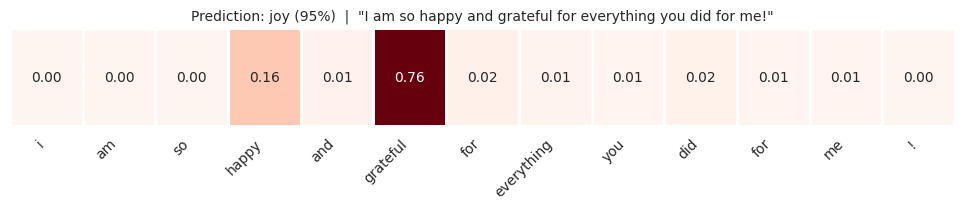

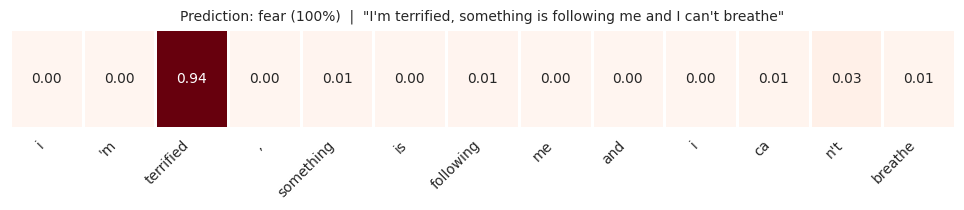

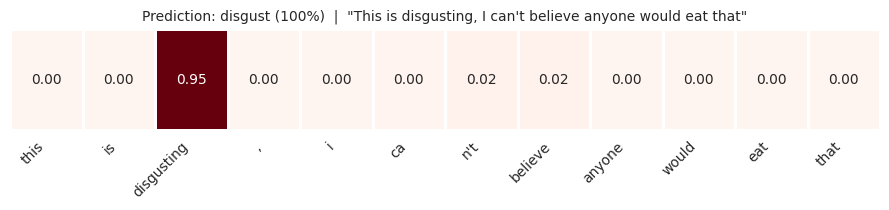

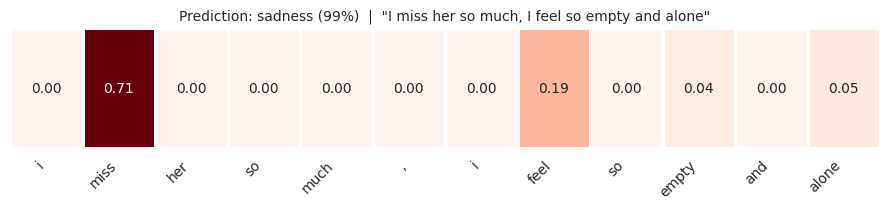

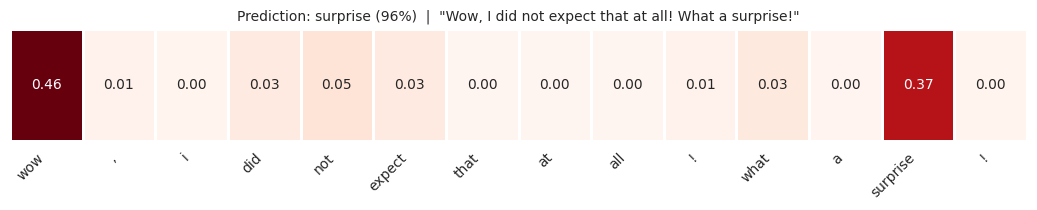

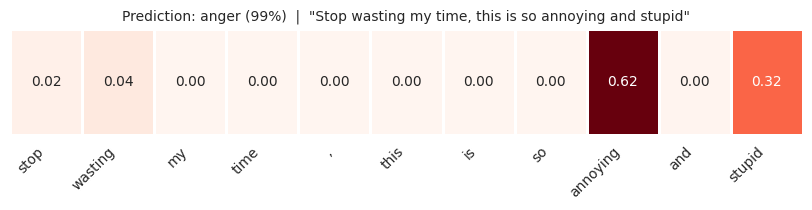

In [27]:
def show_heatmap(text):
    probs, w, toks = predict_with_attention([text])
    toks, weights = toks[0], w[0, :len(toks[0])]
    pred = probs[0].argmax()

    fig, ax = plt.subplots(figsize=(max(6, 0.75 * len(toks)), 2.2))
    sns.heatmap(weights[None, :], annot=True, fmt=".2f", cmap="Reds",
                cbar=False, vmin=0, xticklabels=toks, yticklabels=False,
                linewidths=1, ax=ax)
    ax.set_title(f'Prediction: {id2class[pred]} ({probs[0][pred]:.0%})  |  "{text}"',
                 fontsize=10)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout(); plt.show()

sentences = [
    "I am so happy and grateful for everything you did for me!",
    "I'm terrified, something is following me and I can't breathe",
    "This is disgusting, I can't believe anyone would eat that",
    "I miss her so much, I feel so empty and alone",
    "Wow, I did not expect that at all! What a surprise!",
    "Stop wasting my time, this is so annoying and stupid",
]
for s in sentences:
    show_heatmap(s)

In [28]:
from IPython.display import HTML, display

def html_attention(text):
    probs, w, toks = predict_with_attention([text])
    toks, weights = toks[0], w[0, :len(toks[0])]
    weights = weights / weights.max()             # تطبيع للألوان بس
    spans = "".join(
        f'<span style="background:rgba(255,80,80,{a:.2f});padding:3px 5px;'
        f'margin:2px;border-radius:4px;color:black">{t}</span>'
        for t, a in zip(toks, weights))
    pred = probs[0].argmax()
    return (f"<div style='font-size:16px;margin:8px 0'>{spans} "
            f"&rarr; <b>{id2class[pred]}</b> ({probs[0][pred]:.0%})</div>")

display(HTML("".join(html_attention(s) for s in sentences)))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attention' (of type AttentionLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


--- true = predicted = joy


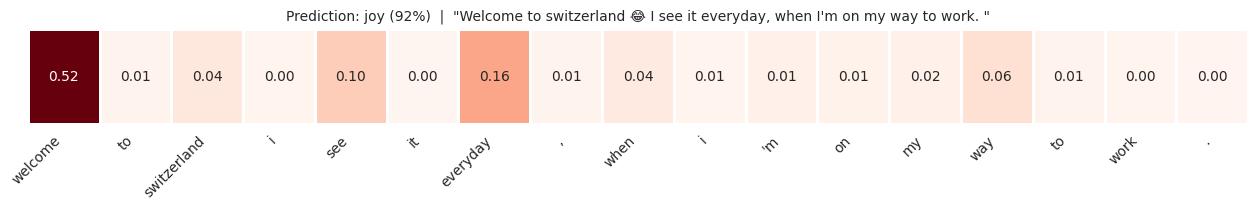

--- true = predicted = sadness


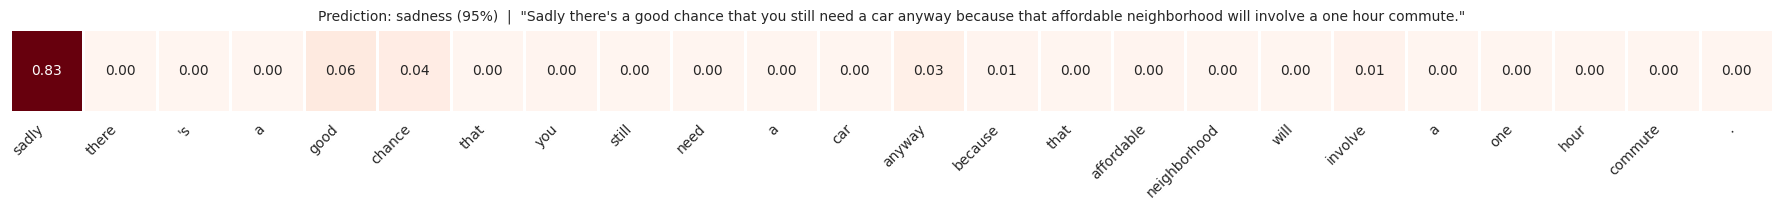

--- true = predicted = anger


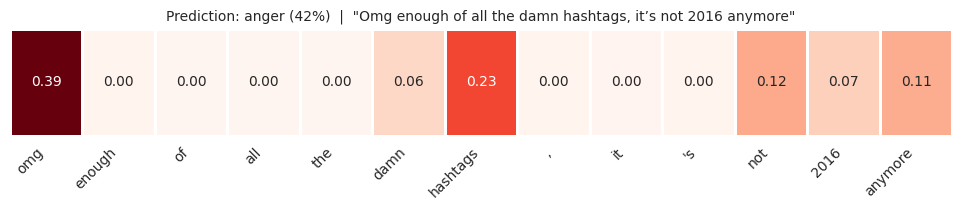

--- true = predicted = fear


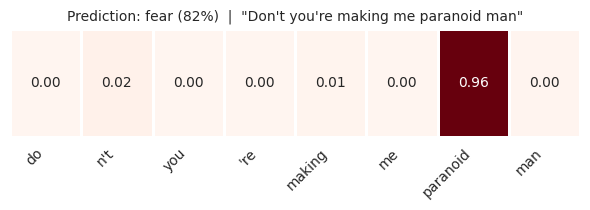

--- true = predicted = surprise


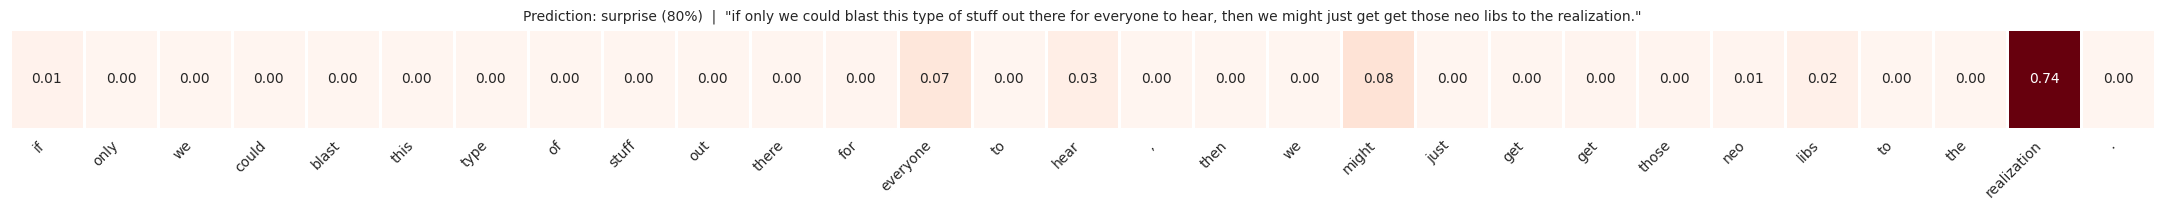

--- true = predicted = disgust


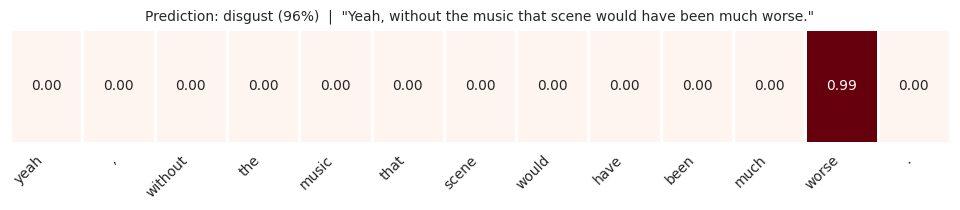

In [29]:
probs_t, W_t = am.predict(X_test, verbose=0)
pred_t = probs_t.argmax(1)

rng = np.random.default_rng(0)
for c in range(6):
    idx = np.where((y_test == c) & (pred_t == c))[0]
    i = rng.choice(idx)
    print(f"--- true = predicted = {id2class[c]}")
    show_heatmap(test6["text"].iloc[i])

In [31]:
from collections import defaultdict

skip = {"<pad>", "<unk>", ".", ",", "!", "?", "'s", "'m", "'re", "'ve", "'ll", "'d", "n't"}
stats = {c: defaultdict(list) for c in range(6)}

for i in np.where(pred_t == y_test)[0]:           # التوقعات الصح بس
    for pos, tok_id in enumerate(X_test[i]):
        if tok_id == 0:
            continue
        word = idx2word[tok_id]
        if word not in skip:
            stats[y_test[i]][word].append(W_t[i, pos])

for c in range(6):
    rows = [(w, np.mean(v), len(v)) for w, v in stats[c].items() if len(v) >= 3]
    top = [r for r in sorted(rows, key=lambda r: -r[1])[:10] if r[1] > 0.2]
    print(f"{id2class[c]:9s}:", ", ".join(f"{w} ({m:.2f})" for w, m, n in top))

joy      : careful (0.86), impressive (0.85), hopefully (0.79), thank (0.77), thanks (0.74), cheers (0.73), enjoying (0.73), hilarious (0.73), beautiful (0.73), beauty (0.72)
sadness  : upset (0.87), awkward (0.87), disappointing (0.83), regret (0.80), wasted (0.78), sad (0.74), sadly (0.73), miss (0.68), shame (0.68), sorry (0.67)
anger    : annoying (0.76), angry (0.71), hell (0.71), frustrating (0.70), downvote (0.68), disagree (0.66), shut (0.64), dumbass (0.63), stupid (0.60), moron (0.58)
fear     : scary (0.92), fear (0.91), afraid (0.91), worried (0.90), horrible (0.79), terrified (0.79), terrifying (0.73), scared (0.69), terrible (0.67)
surprise : realized (0.80), surprised (0.78), wondering (0.77), curious (0.75), realised (0.69), doubt (0.69), surprise (0.68), wonder (0.65), confused (0.65), forgot (0.60)
disgust  : awful (0.85), disgusting (0.85), worse (0.84), weird (0.76)


## 9. Fine-tuning DistilBERT with the HuggingFace Trainer

In [32]:
!pip -q install transformers evaluate accelerate

import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# بنستخدم النص الأصلي (مش المنظّف) لأن DistilBERT له tokenizer خاص
def to_ds(df):
    return Dataset.from_dict({"text": df["text"].tolist(), "label": df["label"].tolist()})

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=64)

train_ds = to_ds(train6).map(tokenize, batched=True)
val_ds   = to_ds(val6).map(tokenize, batched=True)
test_ds  = to_ds(test6).map(tokenize, batched=True)
print(train_ds)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/28104 [00:00<?, ? examples/s]

Map:   0%|          | 0/3527 [00:00<?, ? examples/s]

Map:   0%|          | 0/3539 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 28104
})


In [33]:
from sklearn.metrics import accuracy_score, f1_score

id2label = {i: c for i, c in enumerate(classes)}
label2id = {c: i for i, c in enumerate(classes)}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=6, id2label=id2label, label2id=label2id)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}

cw = torch.tensor([class_weight[i] for i in range(6)], dtype=torch.float)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = torch.nn.functional.cross_entropy(
            outputs.logits, labels, weight=cw.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [35]:
args = TrainingArguments(
    output_dir="distilbert-emotion",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    warmup_steps=350,                 # بدل warmup_ratio=0.1
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer = WeightedTrainer(
    model=model, args=args,
    train_dataset=train_ds, eval_dataset=val_ds,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.321269,0.769523,0.774029,0.661801
2,0.661999,0.730260,0.783102,0.674304
3,0.509327,0.812900,0.795293,0.697910
4,0.387975,0.855638,0.801815,0.702744


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3516, training_loss=0.6679269904027078, metrics={'train_runtime': 318.6241, 'train_samples_per_second': 352.817, 'train_steps_per_second': 11.035, 'total_flos': 1042793579990304.0, 'train_loss': 0.6679269904027078, 'epoch': 4.0})

DistilBERT | Accuracy: 0.7934 | Macro F1: 0.6962

              precision    recall  f1-score   support

         joy      0.937     0.854     0.894      1937
     sadness      0.615     0.674     0.643       298
       anger      0.675     0.704     0.689       609
        fear      0.625     0.765     0.688        85
    surprise      0.675     0.771     0.720       533
     disgust      0.490     0.610     0.543        77

    accuracy                          0.793      3539
   macro avg      0.669     0.730     0.696      3539
weighted avg      0.808     0.793     0.799      3539



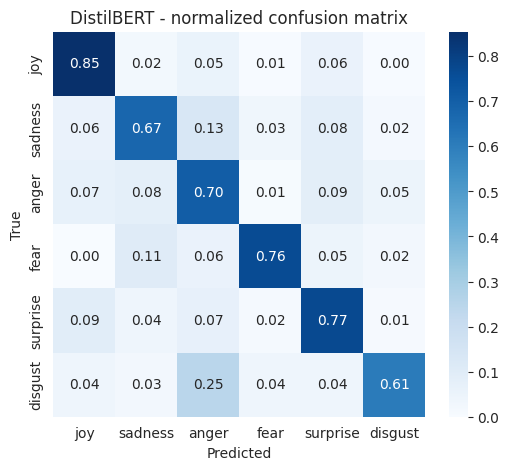

,accuracy,macro_f1
DistilBERT,0.7934,0.6962
BiLSTM+Attention (trainable=True),0.7426,0.6526
LSTM (trainable=True),0.7251,0.6359
GRU (trainable=True),0.7321,0.6289
GRU (trainable=False),0.7098,0.6164
BiLSTM+Attention (trainable=False),0.7056,0.6164
LSTM (trainable=False),0.6917,0.5867


In [36]:
pred_out = trainer.predict(test_ds)
pred = pred_out.predictions.argmax(-1)

acc = accuracy_score(y_test, pred)
f1  = f1_score(y_test, pred, average="macro")
results["DistilBERT"] = {"accuracy": acc, "macro_f1": f1}
print(f"DistilBERT | Accuracy: {acc:.4f} | Macro F1: {f1:.4f}\n")
print(classification_report(y_test, pred, target_names=classes, digits=3))

cm = confusion_matrix(y_test, pred, normalize="true")
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("DistilBERT - normalized confusion matrix")
plt.ylabel("True"); plt.xlabel("Predicted"); plt.show()

pd.DataFrame(results).T.round(4).sort_values("macro_f1", ascending=False)

## 10. Save the model and deployment (Gradio)

In [37]:
trainer.save_model("distilbert-emotion-final")
tokenizer.save_pretrained("distilbert-emotion-final")

!cp -r distilbert-emotion-final /content/drive/MyDrive/emotion_project/

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [38]:
!pip -q install gradio

import gradio as gr
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_DIR = "distilbert-emotion-final"
tok = AutoTokenizer.from_pretrained(MODEL_DIR)
mdl = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).eval()
labels = [mdl.config.id2label[i] for i in range(mdl.config.num_labels)]

EMOJI = {"joy": "😄", "sadness": "😢", "anger": "😠",
         "fear": "😨", "surprise": "😲", "disgust": "🤢"}

def predict(text):
    if not text or not text.strip():
        return "Please enter some text.", None
    enc = tok(text, return_tensors="pt", truncation=True, max_length=64)
    with torch.no_grad():
        probs = torch.softmax(mdl(**enc).logits, dim=-1)[0].tolist()
    top = max(range(len(probs)), key=probs.__getitem__)
    df = pd.DataFrame({"emotion": labels, "probability": probs})
    return f"{EMOJI[labels[top]]} {labels[top].upper()} ({probs[top]:.0%})", df

with gr.Blocks(title="Emotion Classifier") as demo:
    gr.Markdown("# Emotion Classifier\nType a sentence and see which of 6 emotions it expresses.")
    inp = gr.Textbox(label="Your text", lines=3,
                     placeholder="e.g. I can't believe how amazing this is!")
    btn = gr.Button("Analyze", variant="primary")
    out_label = gr.Textbox(label="Dominant emotion")
    out_plot = gr.BarPlot(x="emotion", y="probability", y_lim=[0, 1],
                          title="Confidence per emotion")
    gr.Examples(
        ["I am so happy and grateful for everything!",
         "I'm terrified, something is following me",
         "This is disgusting, I can't believe anyone would eat that",
         "I miss her so much, I feel so empty",
         "Wow, I did not expect that at all!",
         "Stop wasting my time, this is so annoying"],
        inputs=inp)
    btn.click(predict, inp, [out_label, out_plot])
    inp.submit(predict, inp, [out_label, out_plot])

demo.launch(debug=False)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3e2b21929d2ddde9b9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 11. Final comparison (test set, 3,539 comments)

| Model | Accuracy | Macro F1 |
|---|---|---|
| **DistilBERT** | **0.7934** | **0.6962** |
| BiLSTM + Attention (trainable) | 0.7426 | 0.6526 |
| LSTM (trainable) | 0.7251 | 0.6359 |
| GRU (trainable) | 0.7321 | 0.6289 |
| GRU (frozen GloVe) | 0.7098 | 0.6164 |
| BiLSTM + Attention (frozen GloVe) | 0.7056 | 0.6164 |
| LSTM (frozen GloVe) | 0.6917 | 0.5867 |

**Conclusions**
- **DistilBERT is the best model** (+4.4 Macro F1 points over the best recurrent model): pre-training gives contextual word representations, whereas GloVe gives one fixed vector per word.
- Fine-tuning the embeddings (`trainable=True`) clearly helps all recurrent models.
- Among the models trained from scratch, **BiLSTM + Attention** is best and is also the only one that is directly interpretable via attention heatmaps.
- Class weights trade precision for recall on rare classes; **disgust** (524 train examples) stays the hardest class.
- Results come from a single run per model, so small gaps (e.g. LSTM vs. GRU) should not be over-interpreted.